# Exercice 3 — Classifier les chiffres MNIST avec un MLP

Objectif : utiliser des mini-lots et évaluer un modèle sur des données de test.

## 1. Chargement des données et du modèle

In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Appareil :", device)

transform = transforms.ToTensor()

train_dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

Appareil : cuda


100.0%
100.0%
100.0%
100.0%


## 2. Entraîner le modèle pendant 5 époques

`CrossEntropyLoss` attend les sorties brutes du réseau (logits, sans Softmax) et des étiquettes entières.

Époque 1/5 | Perte : 0.3448
Époque 2/5 | Perte : 0.1580
Époque 3/5 | Perte : 0.1083
Époque 4/5 | Perte : 0.0812
Époque 5/5 | Perte : 0.0639


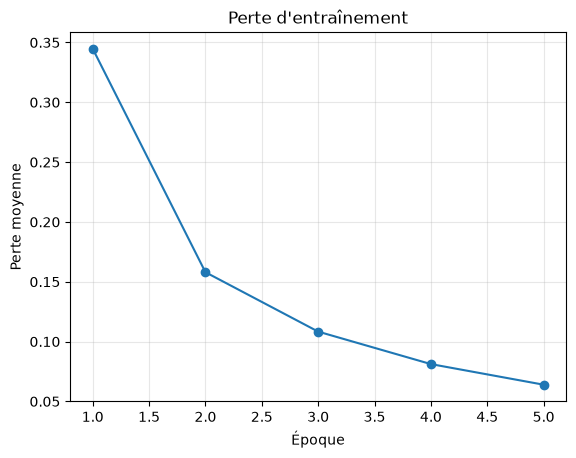

In [2]:
epochs = 5
loss_history = []

for epoch in range(epochs):
    model.train()
    total_loss = 0.0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

    average_loss = total_loss / len(train_dataset)
    loss_history.append(average_loss)
    print(f"Époque {epoch + 1}/{epochs} | Perte : {average_loss:.4f}")

plt.plot(range(1, epochs + 1), loss_history, marker="o")
plt.xlabel("Époque")
plt.ylabel("Perte moyenne")
plt.title("Perte d'entraînement")
plt.grid(alpha=0.3)
plt.show()

## 3. Évaluer sur le jeu de test

On passe en `model.eval()` et `torch.no_grad()`, puis on obtient les classes avec `outputs.argmax(dim=1)`.

In [3]:
model.eval()

all_images, all_labels, all_predictions = [], [], []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images.to(device))
        predicted_classes = outputs.argmax(dim=1)

        all_images.append(images)
        all_labels.append(labels)
        all_predictions.append(predicted_classes.cpu())

all_images = torch.cat(all_images)
all_labels = torch.cat(all_labels)
all_predictions = torch.cat(all_predictions)

print("Images de test évaluées :", len(all_labels))

Images de test évaluées : 10000


### Accuracy, Recall, Precision et F1-score

Avec 10 classes, la précision, le rappel et le F1 sont calculés par classe puis moyennés
(`average="macro"` : chaque chiffre compte autant).

In [4]:
from torcheval.metrics import (MulticlassAccuracy, MulticlassPrecision, MulticlassRecall,
                               MulticlassF1Score, MulticlassConfusionMatrix)

def calculer(metric):
    metric.update(all_predictions, all_labels)
    return metric.compute().item()

accuracy = calculer(MulticlassAccuracy(num_classes=10))
precision = calculer(MulticlassPrecision(num_classes=10, average="macro"))
recall = calculer(MulticlassRecall(num_classes=10, average="macro"))
f1 = calculer(MulticlassF1Score(num_classes=10, average="macro"))

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")

C:\Users\user\Desktop\5IAD G1 BENHAYOUN SADAFI Mohamed, emsi, matiere ia multimodale\Activité Pratique N°1 - Mise en oeuvre du Framework PyTorch\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Accuracy  : 0.9743
Precision : 0.9744
Recall    : 0.9740
F1-score  : 0.9741


### Matrice de confusion

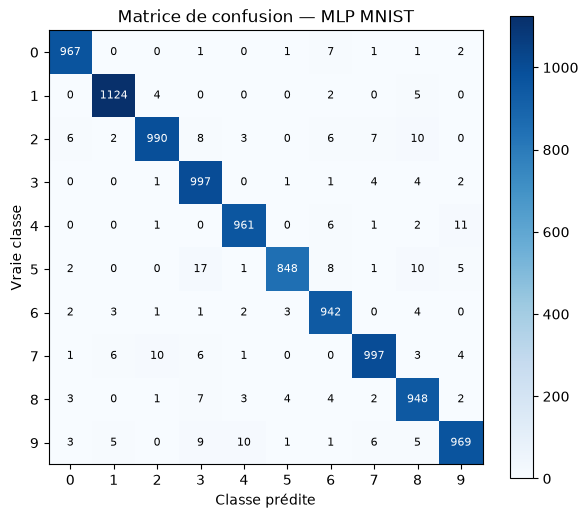

In [5]:
confusion = MulticlassConfusionMatrix(num_classes=10)
confusion.update(all_predictions, all_labels)
matrice = confusion.compute().long()

plt.figure(figsize=(7, 6))
plt.imshow(matrice, cmap="Blues")
for i in range(10):
    for j in range(10):
        valeur = matrice[i, j].item()
        plt.text(j, i, valeur, ha="center", va="center", fontsize=8,
                 color="white" if valeur > matrice.max().item() / 2 else "black")
plt.xticks(range(10))
plt.yticks(range(10))
plt.xlabel("Classe prédite")
plt.ylabel("Vraie classe")
plt.title("Matrice de confusion — MLP MNIST")
plt.colorbar()
plt.show()

La diagonale contient les images bien classées. Les cases hors diagonale montrent les confusions
les plus fréquentes (souvent 4↔9, 3↔5, 7↔2).

### Quelques images mal classées

Nombre d'images mal classées : 257


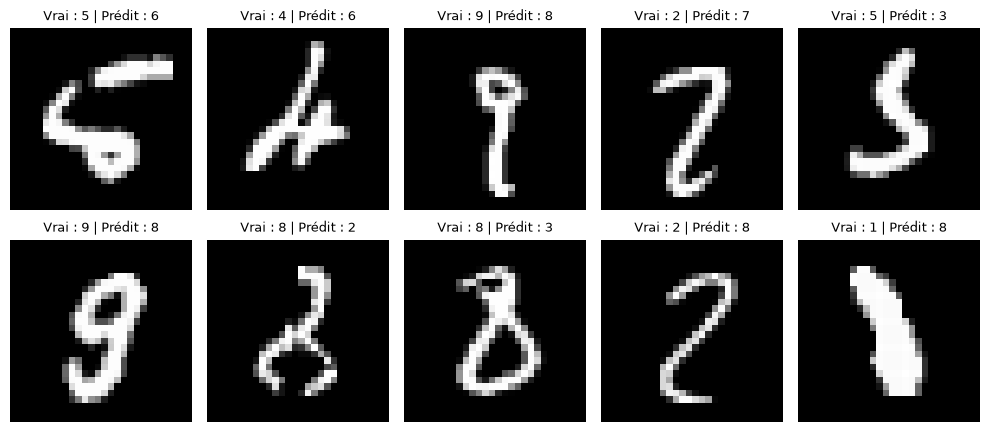

In [6]:
erreurs = (all_predictions != all_labels).nonzero().squeeze(1)
print("Nombre d'images mal classées :", len(erreurs))

fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for ax, idx in zip(axes.flat, erreurs[:10]):
    ax.imshow(all_images[idx, 0], cmap="gray")
    ax.set_title(f"Vrai : {all_labels[idx].item()} | Prédit : {all_predictions[idx].item()}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Sauvegarder et recharger le modèle

On réutilise le réseau entraîné sans recommencer l'apprentissage.

In [7]:
path = "mnist_mlp.pth"
torch.save(model.state_dict(), path)
print("Modèle sauvegardé dans", path)

model_recharge = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
).to(device)
model_recharge.load_state_dict(torch.load(path, weights_only=True))
model_recharge.eval()

with torch.no_grad():
    predictions_recharge = torch.cat([
        model_recharge(images.to(device)).argmax(dim=1).cpu() for images, _ in test_loader
    ])

print("Prédictions identiques :", torch.equal(predictions_recharge, all_predictions))

Modèle sauvegardé dans mnist_mlp.pth
Prédictions identiques : True
